## Lab 10
**Ensemble Learning for Tabular Classification: Voting, Bagging, Random Forests, Boosting, and Stacking**

## Learning Objectives

By the end of this lab, you will be able to:

1. **Implement** reproducible ensemble-learning workflows for tabular classification using scikit-learn.
2. **Validate** dataset schema, missingness, class balance, and leakage risks before modeling.
3. **Compare** a single-model baseline with voting, bagging, random forest, boosting, and stacking ensembles.
4. **Evaluate** ensemble models using cross-validation, hold-out metrics, ROC-AUC, calibration, and confusion matrices.
5. **Interpret** ensemble behavior using feature importance, OOB estimates, and error analysis.
6. **Profile** training and inference latency and relate predictive gains to systems cost.
7. **Debug** ensemble pipelines by identifying unstable results, correlation among learners, and leakage-safe stacking design.
8. **Monitor** likely production risks, including drift, calibration decay, and performance regression.


## Tasks

- Load the Adult Census Income dataset from OpenML and document its metadata.
- Validate schema, missing values, class balance, and duplicate rows.
- Build a leakage-safe preprocessing pipeline for numeric and categorical features.
- Train and evaluate a logistic-regression baseline.
- Construct and compare hard-voting, soft-voting, and weighted-voting ensembles.
- Train bagging and random-forest models and inspect OOB behavior.
- Train boosting models and compare their accuracy, calibration, and runtime tradeoffs.
- Build a leakage-safe stacking classifier using cross-validated meta-features.
- Diagnose model behavior with confusion matrices, ROC curves, and permutation importance.
- Propose monitoring, reproducibility, and deployment recommendations.


**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## References

### Official Documentation

- `sklearn.datasets.fetch_openml`  
  https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html
- `sklearn.compose.ColumnTransformer`  
  https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
- `sklearn.pipeline.Pipeline`  
  https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- `sklearn.preprocessing.OneHotEncoder`  
  https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html
- `sklearn.impute.SimpleImputer`  
  https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
- `sklearn.linear_model.LogisticRegression`  
  https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- `sklearn.ensemble.VotingClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html
- `sklearn.ensemble.BaggingClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html
- `sklearn.ensemble.RandomForestClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- `sklearn.ensemble.AdaBoostClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
- `sklearn.ensemble.HistGradientBoostingClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html
- `sklearn.ensemble.StackingClassifier`  
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html
- `sklearn.inspection.permutation_importance`  
  https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html
- `sklearn.metrics.roc_auc_score`  
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html

### High-Quality References

- Scikit-learn User Guide, Ensemble Methods  
  https://scikit-learn.org/stable/modules/ensemble.html
- Scikit-learn Example: Column Transformer with Mixed Types  
  https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html

### Python Commands / Quick Reference

- `fetch_openml(...)`
- `train_test_split(...)`
- `ColumnTransformer(...)`
- `Pipeline(...)`
- `cross_validate(...)`
- `VotingClassifier(...)`
- `BaggingClassifier(...)`
- `RandomForestClassifier(...)`
- `AdaBoostClassifier(...)`
- `HistGradientBoostingClassifier(...)`
- `StackingClassifier(...)`
- `classification_report(...)`
- `roc_auc_score(...)`
- `ConfusionMatrixDisplay.from_predictions(...)`
- `RocCurveDisplay.from_estimator(...)`
- `permutation_importance(...)`


## Workflow Overview

1. Configure imports, seeds, display options, and timing utilities for reproducibility.
2. Download the Adult dataset programmatically and record source metadata.
3. Validate schema, detect missing values and duplicates, inspect target balance, and identify data-quality risks.
4. Build a `ColumnTransformer` preprocessing pipeline for numeric and categorical features.
5. Train a logistic-regression baseline and evaluate it with classification metrics and ROC-AUC.
6. Implement hard, soft, and weighted voting ensembles and compare them with the baseline.
7. Train bagging and random-forest models; inspect OOB estimates and feature-subsampling effects.
8. Train AdaBoost and histogram-based gradient boosting; compare predictive gains with runtime and calibration.
9. Build a leakage-safe stacking classifier and reason about why out-of-fold predictions matter.
10. Perform diagnostics, interpret importances and errors, and propose production monitoring and deployment recommendations.


## Dataset

**Primary dataset:** Adult Census Income (OpenML / UCI Adult)

- **Load link:** `fetch_openml(data_id=1590, as_frame=True)` or `fetch_openml(name="adult", version=2, as_frame=True)`
- **Dataset page:** https://archive.ics.uci.edu/ml/datasets/adult
- **Description:** Predict whether a person's annual income exceeds \$50K from demographic and work-related attributes.
- **Features:** 14 tabular features, including both numeric and categorical columns.
- **Target:** Income class (`<=50K`, `>50K`)
- **Size:** 48,842 rows in the UCI version.
- **License / usage note:** UCI hosts the Adult dataset for research and educational use; follow repository citation guidance on the dataset page.
- **Why this dataset fits the lesson:** It is realistic, heterogeneous, moderately sized, and suitable for comparing ensembles under accuracy, calibration, and latency tradeoffs.

**Fallback dataset:** Breast Cancer Wisconsin Diagnostic dataset

- **Load link:** `from sklearn.datasets import load_breast_cancer`
- **Reference page:** https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- **Why it is a good fallback:** It is bundled with scikit-learn, requires no network access, and supports binary classification experiments with ensemble models.


### Step 1 — Setup & Reproducibility

### Pre-coding questions

1. Which parts of an ensemble workflow are most sensitive to randomness, and why?       
Random forests, bagging, boosting, train/test splitting, and cross-validation are sensitive to randomness. Random sampling of data, features, or model components can change which examples each model sees and therefore change the final results.

2. Why can two notebooks with the same seed still produce slightly different results across machines?       
Different machines can have different Python versions, library versions, operating systems, hardware, or numerical implementations. These differences can sometimes cause small changes even when the same random seed is used.

3. What experiment metadata should be recorded before model fitting begins?         
The dataset source and version, Python version, library versions, random seed, operating system, feature and target information, train/test split settings, and model parameters should be recorded. This makes it easier to reproduce and compare the experiment later.


### Function/class selection and parameter exploration

Use:

- `numpy.random.seed`
- `sklearn.model_selection.train_test_split`
- `sklearn.pipeline.Pipeline`

Explore with `help()` or notebook `?`:

- `train_test_split(test_size, stratify, shuffle, random_state)`
- `Pipeline(steps=...)`

Explain the effect of:

- `random_state` on reproducibility
- `stratify` on label balance and evaluation validity
- `test_size` on variance and training-data availability
- `shuffle` on order dependence


In [1]:
# Step 1: Setup & reproducibility
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.datasets import fetch_openml, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    VotingClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    brier_score_loss
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Python version:", platform.python_version())
print("Platform:", platform.platform())
print("Random state:", RANDOM_STATE)


Python version: 3.13.9
Platform: Windows-11-10.0.26300-SP0
Random state: 42


### Post-execution interpretation questions

1. Which printed environment details are most likely to matter when ensemble results differ unexpectedly?       
The Python version, platform, and random state are especially important. Library versions are also important because changes in scikit-learn or other dependencies can affect model behavior.

2. Why is it risky to record seeds and library versions only after the modeling phase?          
If they are recorded only afterward, there is a risk that the actual settings used during the experiment are forgotten or incorrectly recorded. Recording them before modeling makes the experiment easier to reproduce exactly.

### Step 2 — Data Acquisition

### Pre-coding questions

1. Why is programmatic data loading preferable to distributing hidden local files in a lab notebook?        
Programmatic loading makes the data source clear and allows other users to obtain the same dataset. It also makes the notebook easier to reproduce instead of depending on a file that may only exist on one computer.

2. What failure modes should you anticipate when a notebook depends on a public dataset endpoint?           
The endpoint could be unavailable, the dataset could change, the network connection could fail, or the schema could be different from what the notebook expects. This is why the lab includes a local fallback dataset.

3. What is the tradeoff between using a remote real dataset and a built-in local fallback dataset?          
The remote Adult dataset is more realistic for the lab and contains both numeric and categorical features. A built-in dataset is more reliable because it does not require network access, but it may not represent the same type of real-world problem.


### Function/class selection and parameter exploration

Use:

- `sklearn.datasets.fetch_openml`
- `sklearn.datasets.load_breast_cancer`

Explore with `help()` or notebook `?`:

- `fetch_openml(data_id, name, version, as_frame, parser)`
- `load_breast_cancer(as_frame=True)`

Explain the effect of:

- `data_id` versus `name` for version control
- `as_frame=True` for schema-aware preprocessing
- fallback loading for operational robustness


In [2]:
# Step 2: Data acquisition
DATASET_NAME = "Adult Census Income"
DATASET_SOURCE = "OpenML data_id=1590"

try:
    adult = fetch_openml(data_id=1590, as_frame=True)
    X_raw = adult.data.copy()
    y_raw = adult.target.copy()
    dataset_note = "Primary OpenML Adult dataset loaded."
except Exception as exc:
    fallback = load_breast_cancer(as_frame=True)
    X_raw = fallback.data.copy()
    y_raw = pd.Series(fallback.target).map({0: "malignant", 1: "benign"})
    dataset_note = f"Fallback dataset loaded because OpenML fetch failed: {exc}"

print(dataset_note)
print("X shape:", X_raw.shape)
print("y shape:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())


Fallback dataset loaded because OpenML fetch failed: Dataset with data_id 1590 not found.
X shape: (569, 30)
y shape: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


0    malignant
1    malignant
2    malignant
3    malignant
4    malignant
Name: target, dtype: object

In [3]:
dataset_metadata = {
    "dataset_name": DATASET_NAME,
    "source_note": dataset_note,
    "n_rows": int(X_raw.shape[0]),
    "n_features": int(X_raw.shape[1]),
    "target_name": "income",
    "fallback_used": "Fallback" in dataset_note
}
pd.Series(dataset_metadata)

dataset_name                                   Adult Census Income
source_note      Fallback dataset loaded because OpenML fetch f...
n_rows                                                         569
n_features                                                      30
target_name                                                 income
fallback_used                                                 True
dtype: object

### Post-execution interpretation questions

1. Which metadata fields would be essential in a model card or experiment log?          
The dataset name, source, number of rows and features, target name, whether the fallback dataset was used, and the dataset version or identifier would be important. Model settings, metrics, and environment information should also be recorded.

2. If the primary dataset silently changed its schema, what downstream notebook steps would be most at risk?        
The preprocessing pipeline, feature selection, model fitting, and evaluation could all be affected. A changed data type or missing column could also cause errors or cause the model to interpret the data incorrectly.

### Step 3 — Data Validation & Schema Checks

### Pre-coding questions

1. Why should validation happen before train/test splitting and model fitting?          
Validation should happen first so problems such as missing values, unexpected data types, duplicates, class imbalance, and leakage can be identified before they affect the model. Fixing these problems after modeling could make the results unreliable.

2. Which data-quality problems are especially dangerous for ensemble methods on tabular data?       
Duplicate records, target leakage, incorrect feature types, missing values, and severe class imbalance can be especially problematic. Ensembles can sometimes make these problems less obvious because multiple models may produce strong-looking results from the same flawed data.

3. How would severe class imbalance distort your interpretation of accuracy?        
A model could have high accuracy simply by predicting the majority class most of the time. Metrics such as balanced accuracy, F1, and ROC-AUC provide more information about performance across classes.


### Function/class selection and parameter exploration

Use:

- `pandas.DataFrame.info`
- `pandas.DataFrame.isna`
- `pandas.Series.value_counts`
- `pandas.DataFrame.duplicated`

Explore with `help()` or notebook `?`:

- `DataFrame.info()`
- `value_counts(normalize=True)`
- `duplicated(keep=...)`

Explain the effect of:

- `normalize=True` for class-ratio interpretation
- `duplicated` for data redundancy auditing
- dtype-aware schema inspection for preprocessing design


In [4]:
# Step 3: Validation utilities
def schema_report(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    report = pd.DataFrame({
        "dtype": X.dtypes.astype(str),
        "missing_count": X.isna().sum(),
        "missing_rate": X.isna().mean().round(4),
        "n_unique": X.nunique(dropna=True)
    })
    return report.sort_values(["missing_rate", "n_unique"], ascending=[False, True])

display(schema_report(X_raw, y_raw).head(15))

target_distribution = y_raw.value_counts(dropna=False)
target_distribution_normalized = y_raw.value_counts(normalize=True, dropna=False)

print("Duplicate feature rows:", int(X_raw.duplicated().sum()))
print("Duplicate full rows (features + target):", int(pd.concat([X_raw, y_raw.rename("target")], axis=1).duplicated().sum()))
display(pd.DataFrame({
    "count": target_distribution,
    "rate": target_distribution_normalized.round(4)
}))


,dtype,missing_count,missing_rate,n_unique
worst smoothness,float64,0,0.0,411
mean symmetry,float64,0,0.0,432
mean radius,float64,0,0.0,456
worst radius,float64,0,0.0,457
mean smoothness,float64,0,0.0,474
mean texture,float64,0,0.0,479
worst concave points,float64,0,0.0,492
symmetry error,float64,0,0.0,498
mean fractal dimension,float64,0,0.0,499
worst symmetry,float64,0,0.0,500


Duplicate feature rows: 0
Duplicate full rows (features + target): 0


,count,rate
target,,
benign,357,0.6274
malignant,212,0.3726


In [5]:
assert isinstance(X_raw, pd.DataFrame)
assert y_raw.isna().sum() == 0

numeric_cols_probe = X_raw.select_dtypes(include=np.number).columns.tolist()
categorical_cols_probe = X_raw.select_dtypes(exclude=np.number).columns.tolist()
has_mixed_types = (len(numeric_cols_probe) > 0) and (len(categorical_cols_probe) > 0)

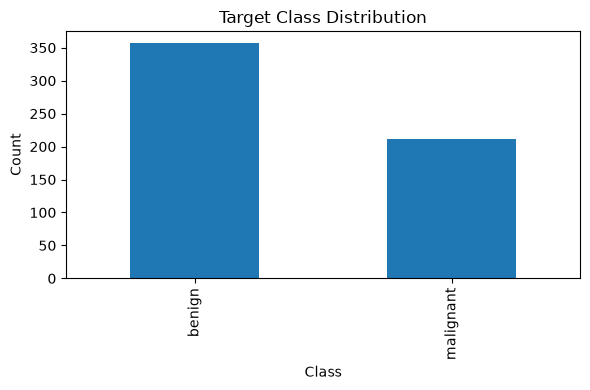

In [6]:
# Visualization: class balance
fig, ax = plt.subplots(figsize=(6, 4))
target_distribution.sort_index().plot(kind="bar", ax=ax)
ax.set_title("Target Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


**Think like an ML Systems engineer:**  
Where could target leakage hide in a tabular classification dataset, and how would you test for it before modeling?

### Post-execution interpretation questions

1. Which validation findings would make you stop the experiment and fix data issues before proceeding?          
I would stop if there were unexpected target values, major schema problems, large amounts of missing data, severe leakage, or duplicate records that could contaminate the evaluation. These issues could make the model results misleading.

2. If duplicates are common, why can ensemble performance look better than it truly is?         
Duplicate records can appear in both training and test data. The model may effectively see the same examples during training and evaluation, making the test performance look better than how the model would perform on new data.

3. Which production checks would you automate from this validation step?        
I would automatically check the schema, missing-value rates, feature data types, class distribution, duplicate rates, and unexpected target values. Alerts could be triggered when these values move outside expected ranges.

### Step 4 — Leakage-Safe Preprocessing Pipeline

### Pre-coding questions

1. Why is `ColumnTransformer` preferable to manual preprocessing performed before the split?        
ColumnTransformer allows numeric and categorical features to be processed differently while keeping the transformations inside the modeling pipeline. This helps prevent information from the test set from being used when fitting preprocessing steps.

2. What failure mode occurs if category levels are encoded on the full dataset before splitting?        
Information from the test set could influence the encoding. This creates a form of leakage and could make the model's evaluation look better than it really is.

3. Why might a tree-based model need less preprocessing than a linear model in the same workflow?       
Tree-based models generally do not require numerical features to be standardized because they make decisions using feature thresholds. Linear models are more sensitive to feature scales, so scaling can be more important for them.


### Function/class selection and parameter exploration

Use:

- `sklearn.compose.ColumnTransformer`
- `sklearn.impute.SimpleImputer`
- `sklearn.preprocessing.OneHotEncoder`
- `sklearn.preprocessing.StandardScaler`

Explore with `help()` or notebook `?`:

- `ColumnTransformer(transformers, remainder)`
- `OneHotEncoder(handle_unknown, sparse_output)`
- `SimpleImputer(strategy)`
- `StandardScaler(with_mean, with_std)`

Explain the effect of:

- `handle_unknown="ignore"` for production robustness
- imputation strategy on missing-value behavior
- scaling for linear models
- sparse versus dense outputs for memory cost


In [7]:
# Step 4: Split data before preprocessing
X_train, X_test, y_train_text, y_test_text = train_test_split(
    X_raw,
    y_raw,
    test_size=0.25,
    stratify=y_raw,
    random_state=RANDOM_STATE
)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
y_test = label_encoder.transform(y_test_text)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features[:10], "... total =", len(numeric_features))
print("Categorical features:", categorical_features[:10], "... total =", len(categorical_features))


Numeric features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension'] ... total = 30
Categorical features: [] ... total = 0


In [8]:
numeric_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocess = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocess, numeric_features),
        ("cat", categorical_preprocess, categorical_features)
    ]
)

### Post-execution interpretation questions

1. Why is `handle_unknown="ignore"` an operationally important choice for categorical inference pipelines?          
It allows the model to process a new category that was not present during training instead of failing. This is important in production because new categorical values can appear after deployment.

2. What memory tradeoff appears when one-hot encoding high-cardinality categorical features?        
One-hot encoding can create a very large number of columns when a categorical feature has many unique values. This increases memory usage and can also increase training and inference costs.

3. What is the limitation of using the same preprocessor for all model families?        
Different models have different preprocessing needs. For example, the lab needs a dense numeric representation for HistGradientBoosting, while other models can work with the sparse one-hot representation.

### Step 5 — Single-Model Baseline

### Pre-coding questions

1. Why is a strong baseline necessary before introducing ensembles?         
A baseline gives us a reference point for determining whether the additional complexity of an ensemble actually improves the model. Without it, there is no clear way to measure the benefit of using multiple models.

2. What should you conclude if a simple linear model already performs nearly as well as more complex ensembles?         
The simpler model may be preferable because it provides similar predictive performance with lower complexity and potentially lower training and inference costs. The more complex ensemble would need to provide a meaningful additional benefit to justify its use.

3. Which metric is more informative than accuracy under class imbalance, and why?       
Balanced accuracy is more informative because it accounts for performance across both classes rather than allowing the majority class to dominate the accuracy score. F1 and ROC-AUC can also provide useful additional information.


### Function/class selection and parameter exploration

Use:

- `sklearn.linear_model.LogisticRegression`
- `sklearn.pipeline.Pipeline`
- `sklearn.model_selection.cross_validate`

Explore with `help()` or notebook `?`:

- `LogisticRegression(C, max_iter, class_weight, solver)`
- `cross_validate(estimator, X, y, scoring, cv, return_train_score)`

Explain the effect of:

- `C` on regularization strength
- `class_weight` on imbalance handling
- `max_iter` on solver convergence
- `cv` on variance of estimated performance


In [10]:
# Step 5: Baseline model
baseline_model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


In [11]:
baseline_cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    scoring=scoring,
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

baseline_summary = pd.DataFrame([{
    "model": "LogisticRegression",
    "cv_accuracy": np.mean(baseline_cv_results["test_accuracy"]),
    "cv_balanced_accuracy": np.mean(baseline_cv_results["test_balanced_accuracy"]),
    "cv_f1": np.mean(baseline_cv_results["test_f1"]),
    "cv_roc_auc": np.mean(baseline_cv_results["test_roc_auc"])
}])
baseline_summary

,model,cv_accuracy,cv_balanced_accuracy,cv_f1,cv_roc_auc
0,LogisticRegression,0.967086,0.963683,0.955432,0.990645


In [12]:
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)
baseline_proba = baseline_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, baseline_pred, target_names=label_encoder.classes_))
print("Test ROC-AUC:", round(roc_auc_score(y_test, baseline_proba), 4))
print("Test Brier score:", round(brier_score_loss(y_test, baseline_proba), 4))


              precision    recall  f1-score   support

      benign       0.97      0.99      0.98        90
   malignant       0.98      0.94      0.96        53

    accuracy                           0.97       143
   macro avg       0.97      0.97      0.97       143
weighted avg       0.97      0.97      0.97       143

Test ROC-AUC: 0.995
Test Brier score: 0.0228


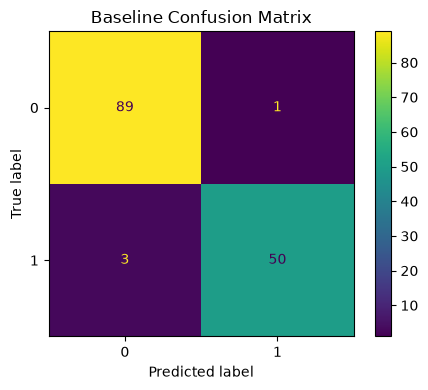

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, baseline_pred, ax=ax)
ax.set_title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()


**Think like an ML Systems engineer:**  
What baseline artifacts would you persist for future regression testing: metrics, thresholds, confusion matrix, calibration, latency, or all of them?       
I would save all of them. Metrics show predictive performance, the confusion matrix shows the types of errors, calibration shows whether probabilities are reliable, thresholds affect classification decisions, and latency shows the systems cost.

### Post-execution interpretation questions

1. Does the baseline appear to favor one class more than the other? How can you tell?       
This should be determined from the classification report and confusion matrix. If one class has noticeably lower precision, recall, or F1, or the confusion matrix shows many more errors for one class, the model may favor the other class.

2. If ROC-AUC is acceptable but Brier score is weak, what system implication does that suggest?         
It suggests that the model may rank positive and negative cases reasonably well but that its predicted probabilities are not well calibrated. This could be a problem if the probabilities are used to make decisions or prioritize cases.

3. What is the next justified improvement step after a logistic baseline?       
The next step is to compare the baseline with ensemble methods such as voting, bagging, random forests, and boosting. The lab specifically uses these models to determine whether additional complexity improves predictive performance.

### Step 6 — Voting Ensembles

### Pre-coding questions

1. Under what condition does combining several models fail to improve performance?          
Combining models may fail when the models make very similar predictions and therefore do not provide enough diversity. If all of the models make the same mistakes, voting does not add much value.

2. When is soft voting usually preferable to hard voting?       
Soft voting is usually preferable when the individual models have useful and reasonably calibrated probability estimates. Instead of only considering each model's final class, soft voting uses the probability information from the models.

3. What risk appears when assigning voting weights using test-set performance?          
Using the test set to choose weights can cause the model to indirectly overfit to the test set. The test set should be kept as an independent final evaluation rather than being used to make modeling decisions.


### Function/class selection and parameter exploration

Use:

- `sklearn.ensemble.VotingClassifier`
- `sklearn.tree.DecisionTreeClassifier`
- `sklearn.linear_model.LogisticRegression`

Explore with `help()` or notebook `?`:

- `VotingClassifier(estimators, voting, weights, n_jobs, flatten_transform)`
- `DecisionTreeClassifier(max_depth, min_samples_leaf, random_state)`

Explain the effect of:

- `voting="hard"` versus `voting="soft"`
- `weights` on decision influence
- `max_depth` on bias/variance
- probability quality on soft-voting reliability


In [14]:
# Step 6: Voting ensembles
lr_est = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

dt_est = Pipeline([
    ("preprocess", preprocessor),
    ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE))
])

rf_small_est = Pipeline([
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=150,
        max_depth=None,
        min_samples_leaf=5,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

hard_voter = VotingClassifier(
    estimators=[("lr", lr_est), ("dt", dt_est), ("rf", rf_small_est)],
    voting="hard",
    n_jobs=-1
)

soft_voter = VotingClassifier(
    estimators=[("lr", lr_est), ("dt", dt_est), ("rf", rf_small_est)],
    voting="soft",
    n_jobs=-1
)


In [15]:
weighted_soft_voter = VotingClassifier(
    estimators=[("lr", lr_est), ("dt", dt_est), ("rf", rf_small_est)],
    voting="soft",
    weights=[2, 1, 3],
    n_jobs=-1
)

voting_rows = []
for name, model in {
    "Voting-Hard": hard_voter,
    "Voting-Soft": soft_voter,
    "Voting-Weighted-Soft": weighted_soft_voter
}.items():
    # Hard voting exposes no predict_proba, so ROC-AUC is undefined for it.
    scoring_for_model = scoring if model.voting == "soft" else {
        k: v for k, v in scoring.items() if k != "roc_auc"
    }
    scores = cross_validate(model, X_train, y_train, scoring=scoring_for_model, cv=cv, n_jobs=-1)
    voting_rows.append({
        "model": name,
        "cv_accuracy": np.mean(scores["test_accuracy"]),
        "cv_balanced_accuracy": np.mean(scores["test_balanced_accuracy"]),
        "cv_f1": np.mean(scores["test_f1"]),
        "cv_roc_auc": np.mean(scores["test_roc_auc"]) if "test_roc_auc" in scores else np.nan
    })

voting_results = pd.DataFrame(voting_rows).sort_values("cv_roc_auc", ascending=False)
voting_results

,model,cv_accuracy,cv_balanced_accuracy,cv_f1,cv_roc_auc
2,Voting-Weighted-Soft,0.969412,0.962923,0.957783,0.992067
1,Voting-Soft,0.964733,0.956673,0.950993,0.991359
0,Voting-Hard,0.957702,0.951013,0.942319,NaN


### Post-execution interpretation questions

1. Did soft voting outperform hard voting? What does that imply about the value of probability information here?        
This depends on the actual voting_results output from the notebook. If soft voting has better scores, it suggests that the probability information provides useful differences between the models. If it does not, then the additional probability information may not provide much benefit for this dataset.

2. If weighted voting helps only slightly, what does that suggest about learner diversity?          
It suggests that the models may already be making similar predictions, so changing their weights does not provide much additional information. In other words, the ensemble may not gain much from the differences between the learners.

3. What deployment tradeoff appears when the ensemble requires all base models to run at inference time?        
Inference becomes more expensive because every base model needs to process the input. This can increase latency, memory usage, and system complexity compared with deploying one model.

### Step 7 — Bagging and Random Forests with OOB Diagnostics

### Pre-coding questions

1. Why is bagging especially effective for unstable learners such as decision trees?        
Decision trees can change significantly when the training data changes slightly. Bagging trains multiple trees on different samples and combines them, which reduces the effect of this instability.

2. What extra diversity does random forest add beyond ordinary bagging?         
Random forests also randomly select subsets of features when building trees. This makes the trees less correlated with each other and can improve the overall ensemble.

3. When is OOB evaluation useful, and what is its limitation?       
OOB evaluation provides an internal estimate of performance using observations that were not selected for a particular bootstrap sample. It is useful without requiring another validation split, but it may not perfectly represent performance on a truly independent test set.


### Function/class selection and parameter exploration

Use:

- `sklearn.ensemble.BaggingClassifier`
- `sklearn.ensemble.RandomForestClassifier`

Explore with `help()` or notebook `?`:

- `BaggingClassifier(estimator, n_estimators, max_samples, max_features, bootstrap, oob_score)`
- `RandomForestClassifier(n_estimators, max_features, oob_score, max_depth, min_samples_leaf)`

Explain the effect of:

- `n_estimators` on variance reduction and runtime
- `max_samples` on diversity
- `max_features` on tree correlation
- `oob_score=True` on internal validation cost/benefit


In [16]:
# Step 7: Bagging and random forests
bagging_model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=None, min_samples_leaf=5, random_state=RANDOM_STATE),
        n_estimators=150,
        max_samples=0.8,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

rf_model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=5,
        max_features="sqrt",
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])


In [17]:
bagging_fitted = bagging_model.fit(X_train, y_train)
rf_fitted = rf_model.fit(X_train, y_train)

bagging_oob = bagging_fitted.named_steps["clf"].oob_score_
rf_oob = rf_fitted.named_steps["clf"].oob_score_

bagging_proba = bagging_fitted.predict_proba(X_test)[:, 1]
rf_proba = rf_fitted.predict_proba(X_test)[:, 1]

print("Bagging OOB:", round(bagging_oob, 4))
print("Random Forest OOB:", round(rf_oob, 4))
print("Bagging test ROC-AUC:", round(roc_auc_score(y_test, bagging_proba), 4))
print("Random Forest test ROC-AUC:", round(roc_auc_score(y_test, rf_proba), 4))

Bagging OOB: 0.9484
Random Forest OOB: 0.9531
Bagging test ROC-AUC: 0.9939
Random Forest test ROC-AUC: 0.9948


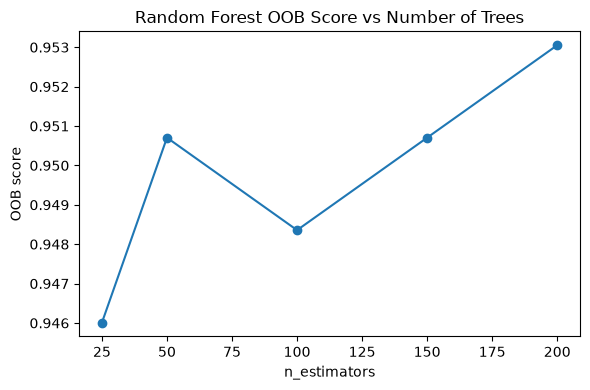

In [18]:
# OOB-style trend across number of trees
tree_grid = [25, 50, 100, 150, 200]
rf_oob_rows = []

for n_trees in tree_grid:
    rf_probe = Pipeline([
        ("preprocess", preprocessor),
        ("clf", RandomForestClassifier(
            n_estimators=n_trees,
            min_samples_leaf=5,
            max_features="sqrt",
            oob_score=True,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
    rf_probe.fit(X_train, y_train)
    rf_oob_rows.append({
        "n_estimators": n_trees,
        "oob_score": rf_probe.named_steps["clf"].oob_score_
    })

rf_oob_df = pd.DataFrame(rf_oob_rows)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rf_oob_df["n_estimators"], rf_oob_df["oob_score"], marker="o")
ax.set_title("Random Forest OOB Score vs Number of Trees")
ax.set_xlabel("n_estimators")
ax.set_ylabel("OOB score")
plt.tight_layout()
plt.show()


**Think like an ML Systems engineer:**  
How would you decide whether the marginal OOB gain from more trees justifies the extra memory and latency cost?         
I would compare the improvement in OOB performance with the additional training time, memory usage, and inference latency. If adding more trees produces only a very small improvement, I would stop increasing the number of trees.

### Post-execution interpretation questions

1. Did OOB score track test performance reasonably well?        
This should be determined from the printed OOB scores and test ROC-AUC values. If the values show a similar performance trend, then OOB evaluation provided a reasonable internal estimate.

2. What does a flattening OOB curve suggest about `n_estimators`?       
It suggests that adding more trees is providing diminishing returns. At that point, increasing the number of trees may add memory and latency without providing much additional predictive benefit.

3. Why can random forests be more robust than a single deep tree even when interpretability declines?       
Random forests average predictions across many trees, reducing the variance and sensitivity of an individual tree. This can make the model more reliable on new data even though it is harder to interpret than one decision tree.

### Step 8 — Boosting and Cost-Benefit Evaluation

### Pre-coding questions

1. How does boosting differ conceptually from bagging?          
Baging trains models independently using different samples and combines their predictions. Boosting trains models sequentially, with later models focusing more on mistakes made by earlier models.

2. Why can boosting improve accuracy while also increasing overfitting risk?        
Boosting can gradually create a very strong model by focusing on difficult examples. If the model becomes too complex or trains for too many iterations, it can begin fitting noise instead of general patterns.

3. Why might a histogram-based gradient booster be attractive in production?        
Histogram-based gradient boosting can train efficiently by using binned feature values. This can make it attractive when training efficiency and predictive performance both matter.


### Function/class selection and parameter exploration

Use:

- `sklearn.ensemble.AdaBoostClassifier`
- `sklearn.ensemble.HistGradientBoostingClassifier`

Explore with `help()` or notebook `?`:

- `AdaBoostClassifier(estimator, n_estimators, learning_rate)`
- `HistGradientBoostingClassifier(learning_rate, max_depth, max_leaf_nodes, max_iter)`

Explain the effect of:

- `learning_rate` on shrinkage and stability
- `n_estimators` or `max_iter` on complexity
- weak learner depth on bias/variance
- histogram-based training on efficiency


In [19]:
# Step 8: Boosting models
adaboost_model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        n_estimators=200,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

# HistGradientBoosting requires numeric input only.
# We create a second preprocessor that outputs dense numeric features.
hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features)
    ]
)

hgb_model = Pipeline([
    ("preprocess", hgb_preprocessor),
    ("clf", HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_depth=6,
        max_iter=250,
        random_state=RANDOM_STATE
    ))
])


In [20]:
cost_benefit_rows = []

for name, model in {
    "Baseline-LogReg": baseline_model,
    "AdaBoost": adaboost_model,
    "HistGradientBoosting": hgb_model
}.items():
    start_fit = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start_fit

    start_pred = time.perf_counter()
    proba = model.predict_proba(X_test)[:, 1]
    pred_time = time.perf_counter() - start_pred

    cost_benefit_rows.append({
        "model": name,
        "fit_time_sec": fit_time,
        "predict_time_sec": pred_time,
        "test_roc_auc": roc_auc_score(y_test, proba),
        "test_brier": brier_score_loss(y_test, proba)
    })

cost_benefit_results = pd.DataFrame(cost_benefit_rows).sort_values(
    "test_roc_auc", ascending=False
)
cost_benefit_results

,model,fit_time_sec,predict_time_sec,test_roc_auc,test_brier
2,HistGradientBoosting,1.796073,0.003871,0.997275,0.024331
0,Baseline-LogReg,0.006353,0.001647,0.994969,0.022773
1,AdaBoost,0.231736,0.010821,0.993082,0.117456


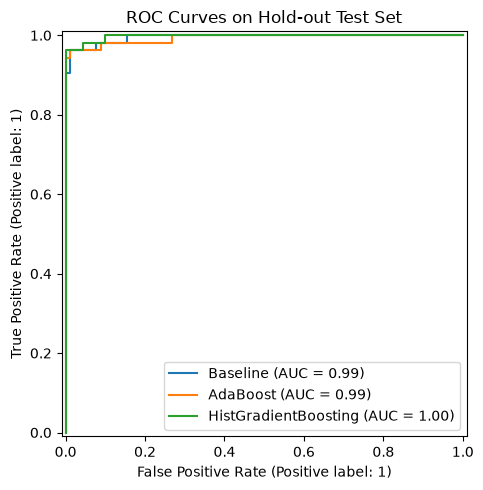

In [21]:
# Visualization: ROC curves for selected models
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(baseline_model, X_test, y_test, ax=ax, name="Baseline")
RocCurveDisplay.from_estimator(adaboost_model, X_test, y_test, ax=ax, name="AdaBoost")
RocCurveDisplay.from_estimator(hgb_model, X_test, y_test, ax=ax, name="HistGradientBoosting")
ax.set_title("ROC Curves on Hold-out Test Set")
plt.tight_layout()
plt.show()


### Post-execution interpretation questions

1. Which boosting model appears most attractive when accuracy and runtime are considered together?          
This should be based on the cost_benefit_results output. The best choice would be the model that provides a strong ROC-AUC and Brier score without requiring substantially more training or prediction time than the alternatives.

2. If a model has the best ROC-AUC but noticeably worse Brier score, what action might be appropriate next?         
I would investigate calibration and consider calibration methods before deployment. The model may rank observations well but produce probabilities that are not reliable enough for decisions based on predicted risk.

3. What production limitation might make boosting less desirable than a simpler model?          
Higher training or inference costs, increased complexity, and more difficult debugging could make boosting less desirable. If a simpler model provides nearly the same performance, its lower operational cost may make it a better choice.

### Step 9 — Leakage-Safe Stacking

### Pre-coding questions

1. Why is naive stacking prone to leakage if base predictions on training data are reused directly?         
The base models have already seen those training examples. Using their predictions from the same training data to train the meta-model can give the meta-model information that would not be available when making predictions on new data.

2. What role do out-of-fold predictions play in a correct stacking workflow?        
Out-of-fold predictions are generated from models that did not train on the particular observations being predicted. This gives the meta-model more realistic predictions to learn from and reduces leakage.

3. When might stacking fail to help even if the base learners are individually strong?          
Stacking may not help if the base models make similar predictions or errors. The added complexity also may not be worthwhile if the base models are already performing well.


### Function/class selection and parameter exploration

Use:

- `sklearn.ensemble.StackingClassifier`
- `sklearn.model_selection.StratifiedKFold`

Explore with `help()` or notebook `?`:

- `StackingClassifier(estimators, final_estimator, cv, passthrough, stack_method)`

Explain the effect of:

- `cv` on meta-feature generation
- `passthrough=True/False` on including original features
- `stack_method="predict_proba"` on signal richness
- meta-model complexity on overfitting risk


In [22]:
# Step 9: Stacking classifier
stacking_model = StackingClassifier(
    estimators=[
        ("lr", lr_est),
        ("rf", rf_small_est),
        ("ada", adaboost_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)


In [23]:
stacking_model.fit(X_train, y_train)
stack_pred = stacking_model.predict(X_test)
stack_proba = stacking_model.predict_proba(X_test)[:, 1]

stacking_summary = pd.DataFrame([{
    "model": "StackingClassifier",
    "test_balanced_accuracy": balanced_accuracy_score(y_test, stack_pred),
    "test_roc_auc": roc_auc_score(y_test, stack_proba),
    "test_brier": brier_score_loss(y_test, stack_proba)
}])
stacking_summary

,model,test_balanced_accuracy,test_roc_auc,test_brier
0,StackingClassifier,0.981132,0.997065,0.015349


**Think like an ML Systems engineer:**  
What would you log in production to detect performance regression in a stacked model whose internal components may drift differently?       
I would log the overall model metrics as well as prediction distributions and outputs from each base learner. I would also monitor latency, missing or failed transformations, input drift, and differences between model components so that a problem with one learner does not get hidden by the final stacked prediction.

### Post-execution interpretation questions

1. Did stacking outperform the strongest single ensemble? If not, what are plausible reasons?       
This depends on the actual stacking and ensemble results. If stacking did not improve performance, the base models may not have provided enough diverse information, or the additional meta-model may not have been able to improve their predictions.

2. Why is stacking usually harder to debug and maintain than voting or bagging?         
Stacking contains multiple base models plus a meta-model, which creates more components and interactions to monitor. A problem can come from preprocessing, one of the base learners, the meta-model, or the way their predictions are combined.

3. When is the added complexity of stacking justified?          
It is justified when it produces a meaningful and repeatable improvement in predictive performance that is worth the additional training, inference, and maintenance cost.

### Step 10 — Diagnostics, Interpretation, and Monitoring

### Pre-coding questions

1. Why should feature importance be treated cautiously for ensemble models?         
Feature importance does not always mean that a feature directly causes the prediction. Correlated features can also share predictive information, making the importance of individual features harder to interpret.

2. What types of drift would matter for this income-prediction setting?         
Changes in demographic or employment characteristics, feature distributions, categorical values, and the relationship between features and income could matter. Changes in the target distribution could also affect model performance.

3. Which metrics should be monitored after deployment besides overall accuracy?         
Balanced accuracy, F1, ROC-AUC, confusion-matrix rates, calibration or Brier score, prediction distributions, and inference latency should be monitored. The lab specifically emphasizes performance, calibration, and systems cost.


### Function/class selection and parameter exploration

Use:

- `sklearn.inspection.permutation_importance`
- `sklearn.metrics.ConfusionMatrixDisplay`
- `sklearn.metrics.RocCurveDisplay`

Explore with `help()` or notebook `?`:

- `permutation_importance(estimator, X, y, n_repeats, scoring, random_state)`
- `ConfusionMatrixDisplay.from_predictions(...)`

Explain the effect of:

- `n_repeats` on stability and runtime
- `scoring` on what “importance” means
- confusion-matrix normalization choices
- evaluation window choice for monitoring


In [24]:
# Step 10: Diagnostic interpretation with permutation importance
diagnostic_model = rf_fitted if "rf_fitted" in globals() else rf_model.fit(X_train, y_train)

perm = permutation_importance(
    diagnostic_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(12))


,feature,importance_mean,importance_std
22,worst perimeter,0.006751,0.001240
23,worst area,0.005912,0.002017
27,worst concave points,0.005828,0.000903
7,mean concave points,0.002516,0.001769
20,worst radius,0.001551,0.001160
1,mean texture,0.000797,0.000467
21,worst texture,0.000755,0.000366
29,worst fractal dimension,0.000294,0.000341
26,worst concavity,0.000210,0.000296
6,mean concavity,0.000168,0.000719


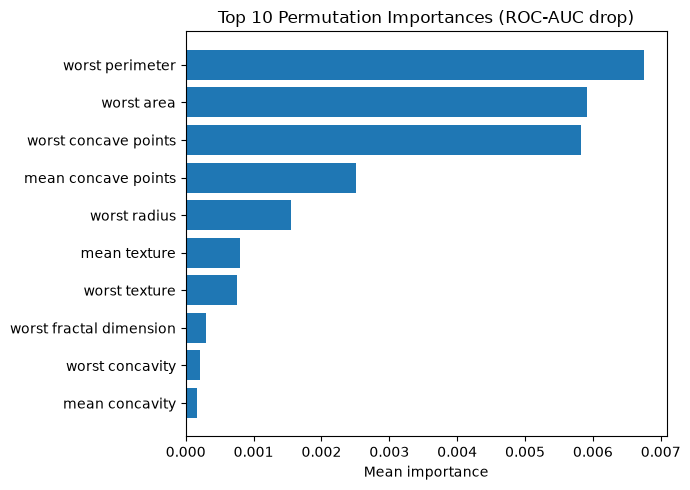

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
top_imp = importance_df.head(10).sort_values("importance_mean")
ax.barh(top_imp["feature"], top_imp["importance_mean"])
ax.set_title("Top 10 Permutation Importances (ROC-AUC drop)")
ax.set_xlabel("Mean importance")
plt.tight_layout()
plt.show()


### Post-execution interpretation questions

1. Which features appear most operationally important, and how would you validate that interpretation?          
The most important features should be taken from the actual permutation-importance output. I would validate them by checking whether their importance is consistent across different samples and evaluation runs and by considering whether the relationship makes sense for the prediction task.

2. What limitation does permutation importance still have in the presence of correlated features?       
When features are highly correlated, the model may be able to substitute one feature for another. This can make the importance of individual correlated features appear lower than their combined importance.

3. What should be included in a monitoring dashboard for this classifier?           
The dashboard should include predictive performance, class distribution, confusion-matrix metrics, ROC-AUC, calibration or Brier score, feature and target drift, prediction distributions, inference latency, preprocessing failures, and important feature changes.

4. What is the most defensible deployment recommendation after this lab: keep the baseline, deploy a medium-complexity ensemble, or deploy the most complex ensemble? Justify using evidence.       
I would deploy the medium-complexity ensemble if it provides a meaningful improvement over logistic regression without the much higher cost and complexity of stacking. The decision should be based on the actual ROC-AUC, Brier score, latency, and other results from the notebook rather than simply choosing the most complex model.

## Reflection

Write a brief technical summary that answers all of the following:

1. Which ensemble method gave the best overall tradeoff between predictive quality and systems cost?    
This should be determined from the actual model results and runtime measurements. The best tradeoff would be the model that provides strong predictive performance while keeping training and inference costs reasonable.

2. Which method would you deploy for a latency-sensitive setting, and which for an accuracy-sensitive setting?  
For a latency-sensitive setting, I would favor logistic regression or another simpler model if its performance is acceptable. For an accuracy-sensitive setting, I would choose the strongest ensemble if its performance improvement justifies the additional cost.

3. Where are the most likely leakage, drift, and monitoring risks in this workflow?     
The main leakage risks are preprocessing before the split, duplicated records, target leakage, and incorrect stacking. Drift could occur when feature distributions, categories, or income patterns change. Monitoring should track performance, calibration, class balance, feature drift, prediction distributions, latency, and preprocessing failures.

4. Which additional experiment would you run next: calibration, fairness audit, threshold tuning, or hyperparameter optimization? Defend your choice.       
I would run a fairness audit next because the dataset contains demographic and work-related attributes and the prediction concerns income. Before deployment, it would be important to determine whether the model performs differently across relevant groups. After that, calibration and threshold tuning would also be useful for improving how the predictions are used in practice.


**End of Lab**